In [1]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Part 1: Introduction to Model Fitting {-}

\lhead{Part 1: Introduction to Model Fitting}

\lfoot{Financial Data Science}

\rfoot{\footnotesize Page \thepage\ of \pageref{LastPage}}

\cfoot{Updated \today}

A fundamental step in many data analyses is to **model** observable data, i.e. to replace the complex processes that generate these data with a mathematically and computationally simpler fiction.

You may have heard the expression "[All models are wrong; some are useful."](https://en.wikipedia.org/wiki/All_models_are_wrong) This is a good mentality to take towards the modelling process: We do not believe that the data were actually generated by, for example, drawing from a normal distribution. Instead, it may be the case that the normal provides a sufficiently accurate approximation to that process.

The process of **fitting a model to data** refers to finding the model within a chosen class of candidates which best fits to a chosen **training set** of data.

Within the field of Statistics, model fitting is often synonymous with **estimation**. Within Machine Learning, this is often called **learning or training a model**. In all cases the same principles apply.

\newpage

**Example:** Modelling the distribution of log returns is of fundamental interest and importance, since it is a crucial ingredient in pricing models and it captures the likelihood of extreme events, among other things.

The package `yfinance` enables access to historical market data.
(I am using version 1.2.0 of `yfinance`.)
There are definitely limitations to using `yfinance`, including **survivorship bias**. But, it is useful as a tool for quickly implementing simple, real-data examples.

The following syntax will scrape the information for a single equity.

In [2]:
symb = "NVDA"
EQdat = yf.Ticker(symb)

**Exercise:** Inspect the output of `dir(EQdat)` to explore what is available.

\answerlines{11}

\newpage

The daily closing price and log daily returns can be obtained as follows:

In [3]:
EQohlc = yf.Ticker(symb).history(start="2023-01-01", end="2025-12-31")
EQldr = np.log(EQohlc['Close']).diff().dropna()

**Comment:** By default, `yfinance` adjusts the closing prices to account for stock splits and dividends. The adjustment is applied in such a way to make the most recent price equal to the market price. If  `auto_adjust=False` is specified, the `Close` column is not adjusted, but there will be an additional column named `Adj Close`.

**Exercise:** Explain the derivation of the log daily returns above.

\answerlines{11}

\newpage

The histogram below compares the observed log daily returns with a normal distribution fit to these data.

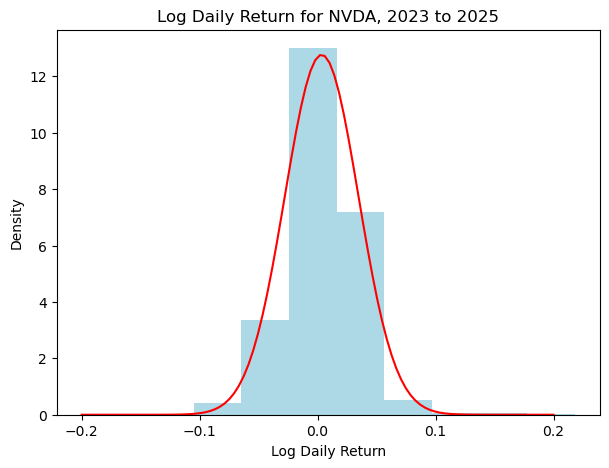

In [4]:
from scipy.stats import norm

plt.figure(figsize=(7, 5))
plt.hist(EQldr, density=True, color="lightblue")
xg = np.linspace(-0.2,0.2,100)
plt.plot(xg, norm.pdf(xg, *norm.fit(EQldr)), color="red")
plt.title(f'Log Daily Return for {symb}, 2023 to 2025')
plt.xlabel('Log Daily Return')
plt.ylabel('Density')
plt.show()

\newpage

**Exercise:** Explore the syntax used in the plot above, including the use of `norm.pdf(xg, *norm.fit(EQldr))`.
    
\answerlines{12}

\newpage

There are a number of questions which the previous example brings up:
    
Why was the normal distribution chosen to fit to these data?

\answerlines{4}

Is the normal distribution a sufficiently good fit?

\answerlines{4}

How does `norm.fit()` fit the model?

\answerlines{4}

How much uncertainty is there in this fit?

\answerlines{4}

\newpage

**This example highlights the following:**
In a situation in which I am working to model observable data, I have a range of choices that I can make regarding both

1. The space of possible models under consideration

2. The method for selecting the best fitting model from among this space

These issues are central to the proper use of methods from Statistics/Data Science/Machine Learning/AI/...

\newpage

The figure below is a simplified, but useful, depiction of the situation.

The outer rectangle represents the space of all possible probability models for a given situation. This includes all possible distributions, and is much larger than we would ever consider in practice.

The ellipse covers the subset of these models which are assumed to be possible. This is the answer to the first question posed above, i.e., it represents everything that the modeller is willing to consider is possible.

The star represents the true model. In this first illustration, the assumed space of models includes the truth. This is an idealistic, but not realistic, situation.

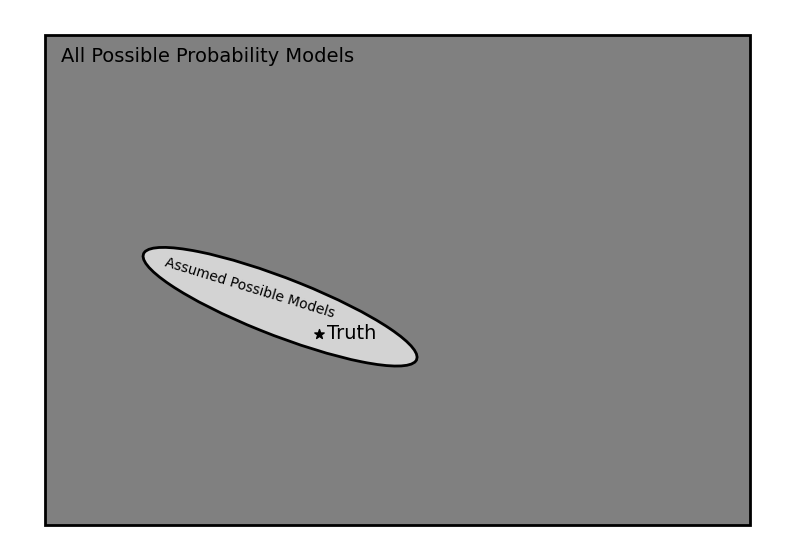

In [5]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Ellipse
import numpy as np

fig, ax = plt.subplots(figsize=[10, 7])
rect = Rectangle((0.05, 0.05), 0.9, 0.9,
                 edgecolor='black', facecolor='gray', linewidth=2)
ax.add_patch(rect)
ax.text(0.07, 0.9, "All Possible Probability Models", size=14)

ax.axis('off')

e = Ellipse((0.35, 0.45), width=0.1, height=0.4, angle=60,
            edgecolor='black', facecolor='lightgray', linewidth=2)
ax.add_patch(e)
ax.text(0.2,0.43,"Assumed Possible Models",rotation=-17)

ax.text(0.41, 0.40, "Truth", size=14, va="center", color="black")
ax.scatter(0.4, 0.4, s=50, color="black",marker="*")

plt.show()

\newpage

Data are used to fit the model, and data are modelled as generated from a probability distribution. Hence, the fit is also random.

The version of the figure shown below highlights this. The blue dots represent the results from repeated fits of the model, each performed with a equivalent sample size, drawn from the same true distribution.

**Exercise:** All of these dots must fall within the ellipse. Why?

\answerlines{4}

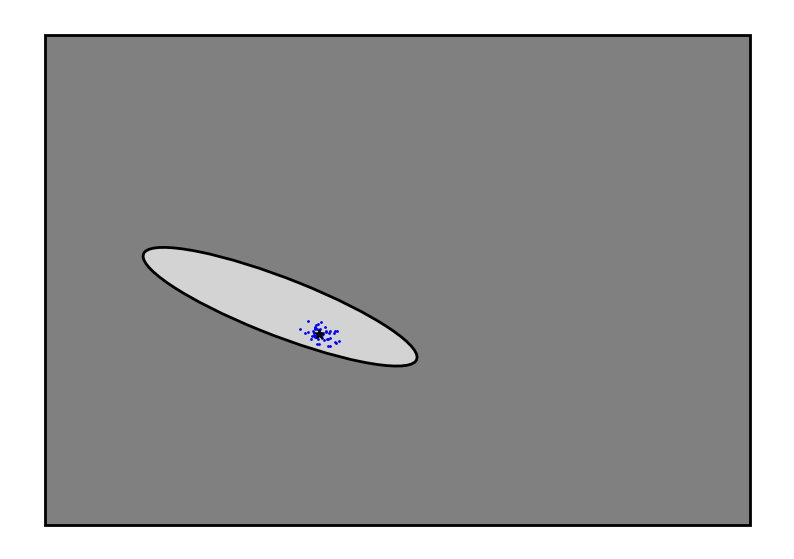

In [6]:
fig, ax = plt.subplots(figsize=[10, 7])
rect = Rectangle((0.05, 0.05), 0.9, 0.9,
                 edgecolor='black', facecolor='gray', linewidth=2)
ax.add_patch(rect)

ax.axis('off')

e = Ellipse((0.35, 0.45), width=0.1, height=0.4, angle=60,
            edgecolor='black', facecolor='lightgray', linewidth=2)
ax.add_patch(e)

ests = np.random.normal(loc=0.4, scale=0.01, size=[50, 2])
sc = ax.scatter(ests[:, 0], ests[:, 1], s=1, color='blue')
sc.set_clip_path(e)

ax.scatter(0.4, 0.4, s=50, color="black",marker="*")

plt.show()

\newpage

The variability in the blue dots (fit models) is crucial, and is central to understanding how the performance of statistical estimators is assessed. It is related to the often-cited **bias-variance tradeoff**.

Bias is present when the fit models are not centered on the truth. This can be viewed as a lack of **accuracy** in the model fit.

Variance is present when the fit models show a great deal of variability, regardless of where they are centered. This is a measure of the **precision** in the fit.

Ideal fits will result from procedures that have both small bias and small variance, i.e., they are created using procedures which are both accurate and precise.

The following pages will consider different scenarios, and depict potential sources of bias and variance.

\newpage

In the case below, the fit is **unbiased** because they are centered on the truth, but the variance is larger due to the increased variability in the estimator being used. 

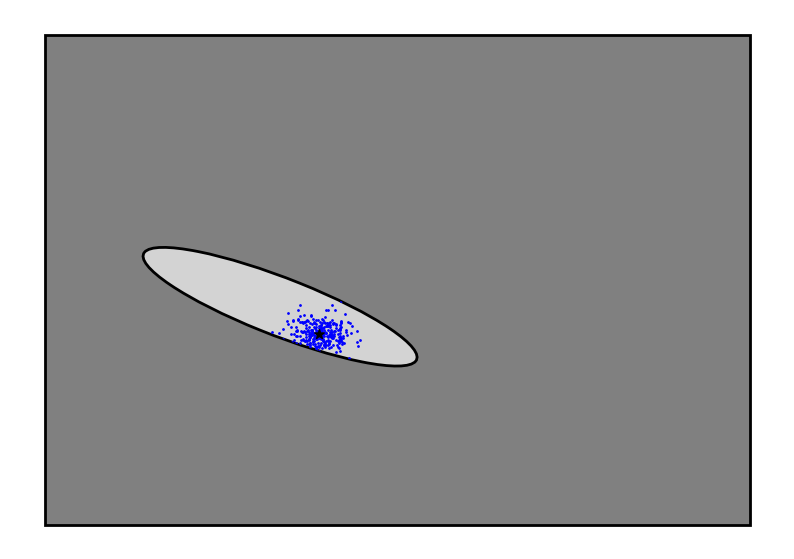

In [7]:
fig, ax = plt.subplots(figsize=[10, 7])
rect = Rectangle((0.05, 0.05), 0.9, 0.9,
                 edgecolor='black', facecolor='gray', linewidth=2)
ax.add_patch(rect)

ax.axis('off')

e = Ellipse((0.35, 0.45), width=0.1, height=0.4, angle=60,
            edgecolor='black', facecolor='lightgray', linewidth=2)
ax.add_patch(e)

ests = np.random.normal(loc=0.4, scale=0.02, size=[300, 2])
sc = ax.scatter(ests[:, 0], ests[:, 1], s=1, color='blue')
sc.set_clip_path(e)

ax.scatter(0.4, 0.4, s=50, color="black",marker="*")

plt.show()

\newpage

In this next example, the variance is reduced, but there is clear bias since the fits are not centered on the truth. Again, it is evident that we would ideally have both low bias and low variance.

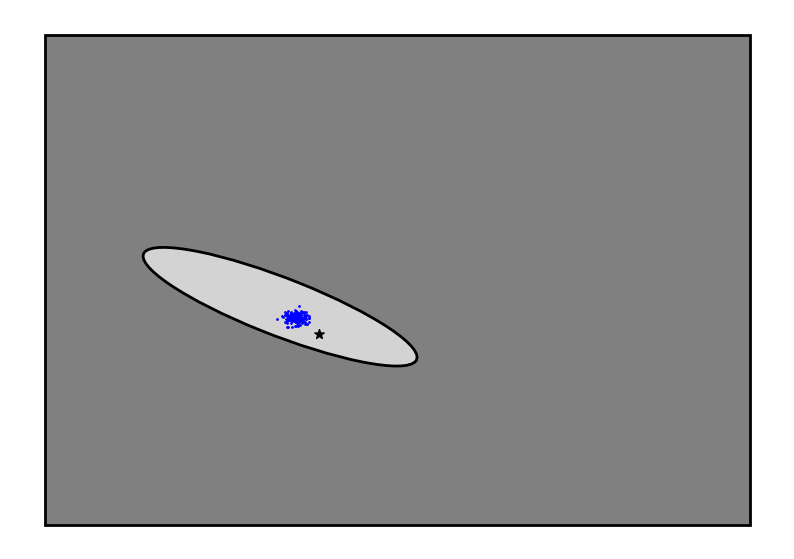

In [8]:
fig, ax = plt.subplots(figsize=[10, 7])
rect = Rectangle((0.05, 0.05), 0.9, 0.9,
                 edgecolor='black', facecolor='gray', linewidth=2)
ax.add_patch(rect)

ax.axis('off')

e = Ellipse((0.35, 0.45), width=0.1, height=0.4, angle=60,
            edgecolor='black', facecolor='lightgray', linewidth=2)
ax.add_patch(e)

ests = np.random.normal(loc=[0.37,0.43], scale=0.007, size=[200, 2])
sc = ax.scatter(ests[:, 0], ests[:, 1], s=1, color='blue')
sc.set_clip_path(e)

ax.scatter(0.4, 0.4, s=50, color="black",marker="*")

plt.show()

\newpage

Bias can also be a result of a poorly specified model. In this example, the variance is small, but there is evident bias because the assumed models are not close to the truth.

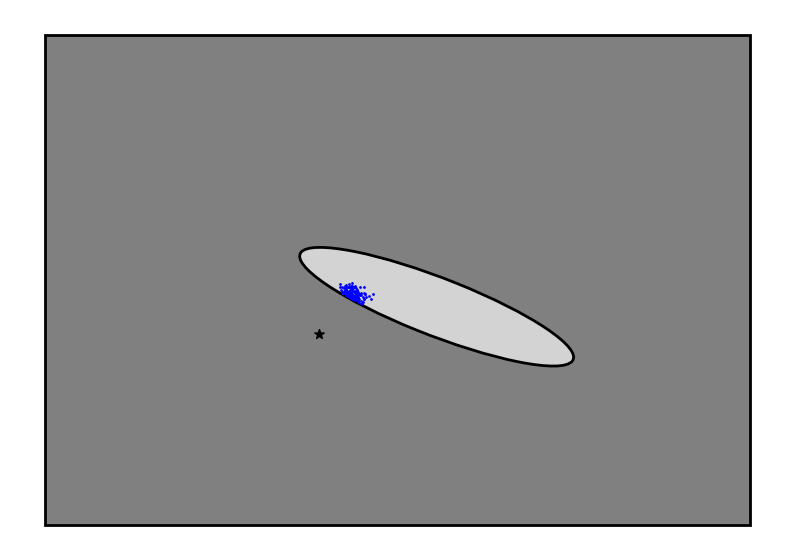

In [9]:
fig, ax = plt.subplots(figsize=[10, 7])
rect = Rectangle((0.05, 0.05), 0.9, 0.9,
                 edgecolor='black', facecolor='gray', linewidth=2)
ax.add_patch(rect)

ax.axis('off')

e = Ellipse((0.55, 0.45), width=0.1, height=0.4, angle=60,
            edgecolor='black', facecolor='lightgray', linewidth=2)
ax.add_patch(e)

ests = np.random.normal(loc=[0.44,0.47], scale=0.01, size=[200, 2])
sc = ax.scatter(ests[:, 0], ests[:, 1], s=1, color='blue')
sc.set_clip_path(e)

ax.scatter(0.4, 0.4, s=50, color="black",marker="*")

plt.show()

\newpage

An effective way of reducing bias is to expand the class of models under consideration.
The "tradeoff" comes in, however, in that this requires the use of models which have a more parameters to estimate (hence greater flexibility) and is accompanied by a corresponding increase in the variance.

This is the hallmark of the bias-variance tradeoff: Expanding the class of models under consideration generally means more parameters to estimate, i.e., a more flexible model. The more parameters, the more data that are required to estimate those parameters well.

Models with more flexibility also increase the risk of **overfitting**, a problematic situation in which a model fits well to the training sample, but does not extend well to the larger population.

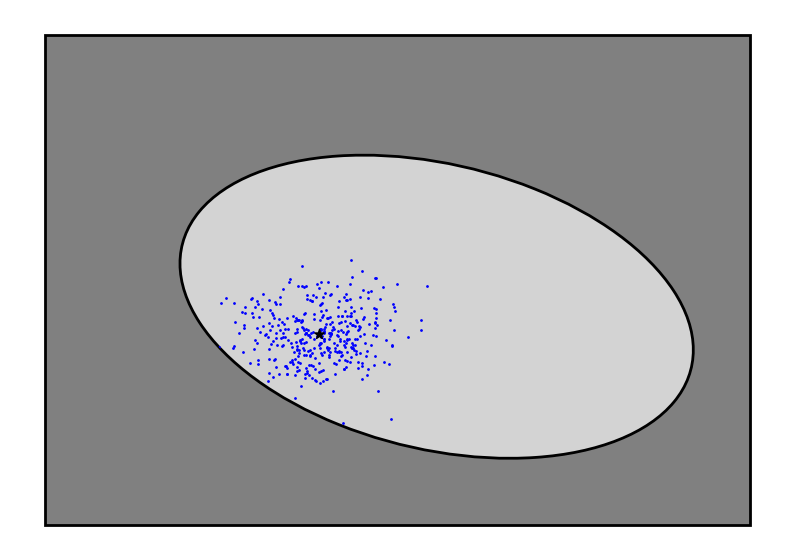

In [10]:
fig, ax = plt.subplots(figsize=[10, 7])
rect = Rectangle((0.05, 0.05), 0.9, 0.9,
                 edgecolor='black', facecolor='gray', linewidth=2)
ax.add_patch(rect)

ax.axis('off')

e = Ellipse((0.55, 0.45), width=0.5, height=0.7, angle=60,
            edgecolor='black', facecolor='lightgray', linewidth=2)
ax.add_patch(e)

ests = np.random.normal(loc=[0.4,0.4], scale=0.05, size=[400, 2])
sc = ax.scatter(ests[:, 0], ests[:, 1], s=1, color='blue')
sc.set_clip_path(e)

ax.scatter(0.4, 0.4, s=50, color="black",marker="*")

plt.show()

\newpage

Generally, the only way to achieve low variance fits when using a flexible model is to obtain a (much) larger sample.

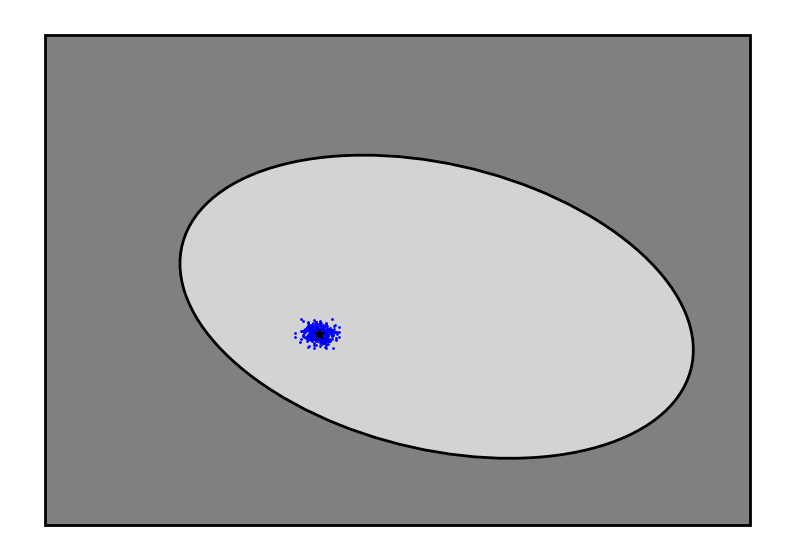

In [11]:
fig, ax = plt.subplots(figsize=[10, 7])
rect = Rectangle((0.05, 0.05), 0.9, 0.9,
                 edgecolor='black', facecolor='gray', linewidth=2)
ax.add_patch(rect)

ax.axis('off')

e = Ellipse((0.55, 0.45), width=0.5, height=0.7, angle=60,
            edgecolor='black', facecolor='lightgray', linewidth=2)
ax.add_patch(e)

ests = np.random.normal(loc=[0.4,0.4], scale=0.01, size=[400, 2])
sc = ax.scatter(ests[:, 0], ests[:, 1], s=1, color='blue')
sc.set_clip_path(e)

ax.scatter(0.4, 0.4, s=50, color="black",marker="*")

plt.show()

\newpage

The modeller could be very smart (or lucky) and use a model that is both restrictive and includes the truth. In this case the bias and variance will be limited regardless of the approach used to fit the model. This is not  realistic, however.

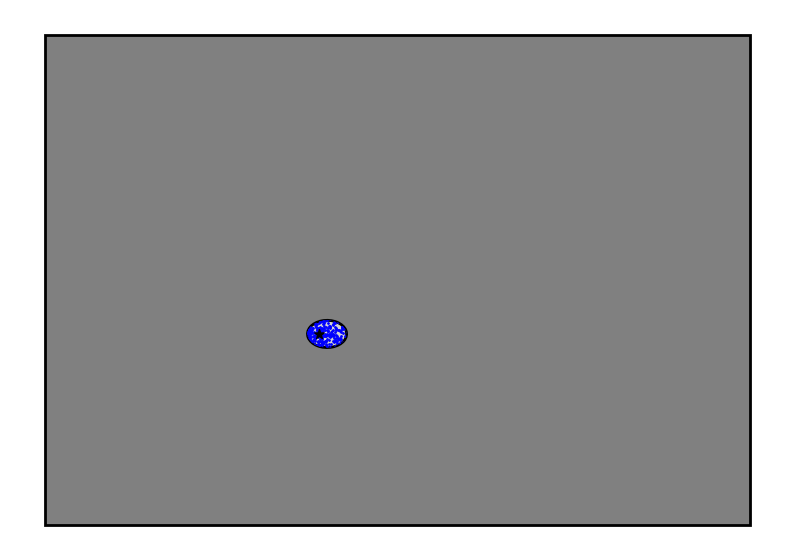

In [12]:
fig, ax = plt.subplots(figsize=[10, 7])
rect = Rectangle((0.05, 0.05), 0.9, 0.9,
                 edgecolor='black', facecolor='gray', linewidth=2)
ax.add_patch(rect)

ax.axis('off')

e = Ellipse((0.41, 0.40), width=0.05, height=0.05, angle=60,
            edgecolor='black', facecolor='lightgray', linewidth=2)
ax.add_patch(e)

ests = np.random.normal(loc=[0.4,0.4], scale=0.02, size=[400, 2])
sc = ax.scatter(ests[:, 0], ests[:, 1], s=1, color='blue')
sc.set_clip_path(e)

ax.scatter(0.4, 0.4, s=50, color="black",marker="*")

plt.show()

\newpage

Taking all of this together, we note the following:

Large **bias** results from two sources: First, the assumed class of models may not be close to including the true model. Second, the chosen fitting procedure for the model is itself not accurate. In either of these two cases, no amount of data will reduce the bias. In fact, larger samples can make the problem of bias more evident.

Large **variance** also results from two sources: First, the model class may be chosen too broad and there is insufficient data to constrain all of the parameters of such a flexible model. Second, the estimator chosen for the unknown parameters may lack precision. In either of these two cases, obtaining more data should reduce the variance.

\newpage

**Comment:** The classic bias-variance tradeoff described above states that pushing model flexibility too far results in overfitting and high variance. This behavior is crucial for understanding the fitting of standard models. However, in modern, highly over-parameterized models (where the number of parameters vastly exceeds the number of observations), we frequently observe a phenomenon known as **double descent**.

Once a model possesses enough capacity to perfectly interpolate the training data (the **interpolation threshold**), optimization algorithms such as gradient descent implicitly smooth (regularize) the model. In this regime, adding even more parameters can actually cause the variance and test set error to decrease a second time.

\newpage

Returning to the log returns example of above, we could consider a different model using the **generalized normal distribution**, which has density as follows:
\begin{equation*}
   f(x) = \frac{\beta}{2\alpha \Gamma\left(\frac{1}{\beta}\right)} \exp\left( -\left| \frac{x-\mu}{\alpha} \right|^\beta \right),\:\:\: -\infty < x < \infty,
\end{equation*}
where $\alpha>0$, $\beta>0$, and $\mu$ are parameters, and $\Gamma$ is the **gamma function**. 

This distribution is symmetric around $\mu$, and the variance is given by
\begin{equation*}
  \mathbb{V}(X) = \frac{\alpha^2 \Gamma(3/\beta)}{\Gamma(1/\beta)}
\end{equation*}

When $\beta=2$, this is the normal distribution. For $\beta>2$, the tails will be lighter than the normal, and $\beta<2$ gives tails heavier than normal.

\newpage

In Python, this is implemented via `gennorm` in scipy.stats. 
The code below will allow you to explore the shape of the density.

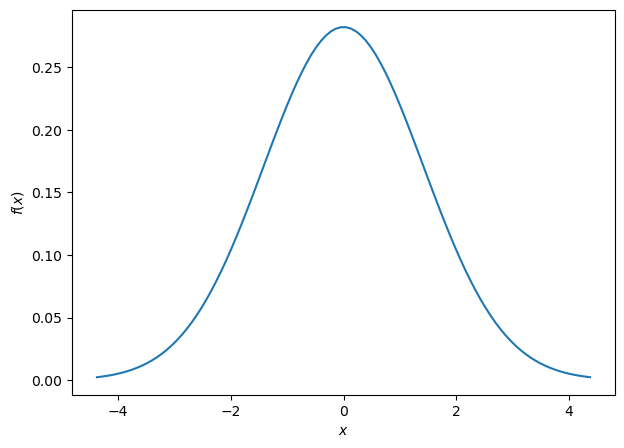

In [13]:
from scipy.stats import gennorm

alpha = 2; beta = 2; mu = 0

plt.figure(figsize=(7, 5))
gndist = gennorm(beta,mu,alpha)

xg = np.linspace(gndist.ppf(0.001),gndist.ppf(0.999),100)
plt.plot(xg, gndist.pdf(xg))
plt.xlabel('$x$')
plt.ylabel('$f(x)$')
plt.show()

\newpage

The figure below compares the fits to our data set.

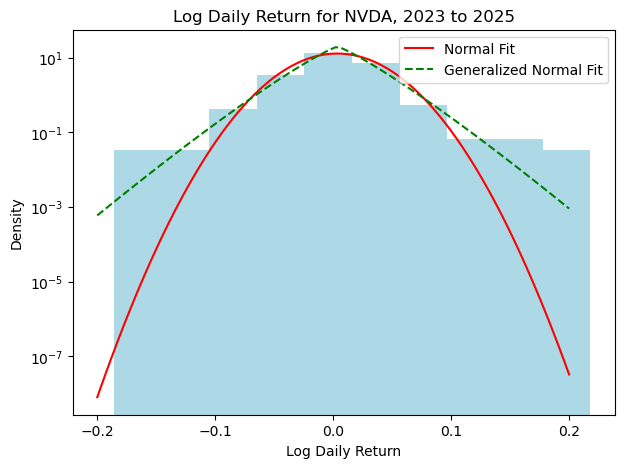

In [14]:
plt.figure(figsize=(7, 5))
plt.hist(EQldr, density=True, color="lightblue")
xg = np.linspace(-0.2,0.2,100)
plt.plot(xg, norm.pdf(xg, *norm.fit(EQldr)), color="red",label="Normal Fit")
plt.plot(xg, gennorm.pdf(xg, *gennorm.fit(EQldr)), color="green",label="Generalized Normal Fit",linestyle="--")
plt.title(f'Log Daily Return for {symb}, 2023 to 2025')
plt.xlabel('Log Daily Return')
plt.ylabel('Density')
plt.yscale('log')
plt.legend()
plt.show()

\newpage

Let's make this discussion more mathematical.

The probability models we assume are often fully-specified, except for some unknown real-valued **parameters**.

We use available data (a **sample**) to estimate these parameters, i.e., to fit the model.

**In our example above**, we pose a model which assumes that the log daily returns can be represented as random variables $X_1, X_2, \ldots, X_n$ which are **independent and identically distributed (iid)** with the normal distribution with mean $\mu$ and variance $\sigma^2$. These two parameters ($\mu$ and $\sigma^2$) are unknown, and must be estimated from data.

\newpage

## Terminology {-}

The **parameters** are the constants that distinguish probability models in the same **family**. Examples of families include things such as "normal" and "exponential," but also classes of regression models, e.g., "linear models."

A **statistic** is a function of the RVs being used to model the observable data. Examples include the sample mean, the sample variance, etc. A statistic is a **random variable**.

An **estimator** is a statistic which is used to estimate an unknown parameter or a function of an unknown parameter. It is also a random variable.

The **hat notation** is standard for denoting an estimator: $\widehat \beta$ is an estimator
for $\beta$, for example. $\theta$ is often used to denote a generic parameter, and $\widehat \theta$ is an estimator for $\theta$.

**Exercise:** Explain why an estimator is appropriately thought of as a random variable.

\answerlines{8}

\newpage

An estimator $\widehat \theta$ is an **unbiased estimator for $\theta$** if $\mathbb{E}(\widehat \theta) = \theta$.
Unbiased estimators are **optimally accurate** since they have the smallest possible bias, where the amount of bias is usually quantified as
\begin{equation*}
   {\rm bias}^2(\widehat \theta) = (\mathbb{E}(\widehat \theta) - \theta)^2.
\end{equation*}

**Comment:** It does not make sense to just say that "$\widehat \theta$ is an unbiased estimator." This statement does not clarify what it is an unbiased estimator of. (Every estimator is an unbiased estimator of
its expected value, for example.)

The variance of an estimator $\mathbb{V}(\widehat \theta)$ captures the **precision** of the estimator. The square root of the variance of an estimator is called the **standard error (SE)** of the estimator.

The **mean squared error (MSE) of an estimator of $\theta$** makes a connection between the squared error in an estimator,  the amount of bias, and the amount of variance:
\begin{equation*}
   {\rm MSE}(\widehat \theta) = \mathbb{E}(\widehat \theta - \theta)^2 = \mathbb{V}(\widehat \theta) + {\rm bias}^2(\widehat \theta).
\end{equation*}

MSE gives a natural way of comparing estimators: We prefer an estimator with a smaller MSE. MSE also makes more  clear the role of **both** bias and variance in determining the quality of an estimator.

\newpage

**Exercise:** Suppose that $X_1, X_2, \ldots, X_n$ are iid normal with mean $\mu$ and variance $\sigma^2$, with $n > 1000$. To make things simpler, let's assume that $\sigma^2$ is known, but $\mu$ needs to be estimated. Consider three estimators for $\mu$:
\begin{equation*}
   \widehat \mu_1 = \overline{X}, \:\:\:\:\widehat \mu_2 = \frac{1}{10}\sum_{i=1}^{10} X_i, \:\:\:\:\widehat \mu_3 = 0.
\end{equation*}
What are the bias, variance, SE, and MSE of each of these estimators of $\mu$?

\answerlines{17}

\newpage

**Exercise:** In the previous exercise, where did we use the assumption that the random variables are normally distributed?
    
\answerlines{5}

It may seem natural that, under general conditions, the sample mean $\overline{X}$ is the best estimator for the population mean. The variance is a little trickier. The classic **sample variance** is defined as follows:
\begin{equation*}
   s^2 = \frac{1}{n-1} \sum_{i=1}^n \left(X_i - \overline{X}\right)^2.
\end{equation*}
The sample standard deviation $(s)$ is the square root of this.

It is possible to prove (it is more tedious than difficult) that if $X_1, X_2, \ldots,X_n$ have the same mean and the same variance $\sigma^2$, and that these random variables are uncorrelated (meaning that every pair has a correlation of zero), then $s^2$ is an unbiased estimator of $\sigma^2$.

\newpage

**Exercise:** Is there a heuristic way of seeing why it is better to divide by $n-1$, as opposed to by $n$, when estimating the variance?

\answerlines{20}

\newpage

In Python, `np.mean`, `np.var`, and `np.std` calculate the sample mean, the sample variance, and the sample standard deviation, respectively, but only if `ddof=1` is specified:

In [15]:
print("sample mean:",np.mean(EQldr))
print("sample variance:",np.var(EQldr,ddof=1))
print("sample SD:", np.std(EQldr,ddof=1))

sample mean: 0.0034315795993921346
sample variance: 0.0009779460261378841
sample SD: 0.03127212858341888


Compare this with what is obtained from `norm.fit` from scipy.stats:

In [16]:
print(norm.fit(EQldr))

(np.float64(0.0034315795993921346), np.float64(0.03125127354369792))


**Exercise:** It is evident that `norm.fit` is **not** using the sample SD to fit the model. Why not?

\answerlines{7}

\newpage

## Reporting Estimates {-}

It is always a good idea to think about how results are communicated, and that includes results from parameter estimation procedures.

Consider first the role of bias. Unbiasedness is a property of the **estimator**, not of the **estimate**. In other words, it is a property of the **procedure**, not of the **result of that procedure**.

For this reason, it is not correct to say that, for example, "10.5 is an unbiased estimate of $\mu$." Instead, say that "Our estimate of $\mu$ is 10.5. It was found using an estimator known to be unbiased."

Variance is also important in interpreting an estimate, so it is standard to report the SE along with an estimate. Again, however, keep in mind that the SE is a property of the estimator, and not of the estimate, since it is a statement about how the estimator performs in repeated use.

So, do not state "The SE of our estimate is 2.6." Instead, write something more clear, such as "The SE of our estimator is 2.6. Hence, the estimator used in this case typically gives errors on the order of 2.6."

\newpage

Standard errors are the most common way of reporting uncertainty in an estimator.

Another approach that is often used is **confidence intervals**. Heuristically, a confidence interval is a range of values within which we are fairly confident the true value of the parameter falls.

Mathematically, an interval $(L,U)$ is a **$100(1-\alpha)\%$ confidence interval** for $\theta$ if
$P(L \leq \theta \leq U) = 1-\alpha$.

It is common to see 95% intervals reported. Less common are 90% and 99% intervals. Any other choice is even less common. (Although physicists are fond of 68% intervals. Why?)

What is often confusing about this construction is that it is $L$ and $U$ which are random, **not** the
parameter $\theta$.

\newpage

**Exercise:** Suppose that $\widehat \theta$ is an unbiased estimator for $\theta$, and further that $\widehat \theta$ is (approximately) normally distributed. Show that
\begin{equation*}
   \widehat \theta \pm 2 \times {\rm SE}(\widehat \theta) 
\end{equation*}
is an (approximate) 95% confidence interval for $\theta$.

\answerlines{17}

\newpage

**Exercise:** Suppose that $X_1, X_2, \ldots, X_n$ are iid from some distribution with mean $\mu$ and variance $\sigma^2$. You can assume that $n > 100$. Construct a 95% confidence interval for $\mu$.

\answerlines{19}